# 情感分析-高级：时间序列（课后作业 · 程序2）

> **课程**：第四讲　感知世界：识别与理解文本中的情感
> **作业要求**：完成"程序2·时间线的程序"
> **完成人**：（学习者本人）
> **任务链**：读取 Excel → 批量计算每条评论的情感值 → 画情感随时间的**折线图** → 定位异常评论并分析原因。

数据文件：`restaurant-comments.xlsx`（某火锅店 27 条点评，2017-02 ~ 2017-05）。

### 工作步骤

1. 能够知道如何处理 Excel 文件（`pandas`）；
2. 怎么用 `snownlp` 处理一句话的情感，生成情感值；
3. 如何按行、批量地快速生成每条文本的情感值（`.apply`）；
4. 怎么把情感的趋势线画出来（**折线图**，而不是讲义里的散点图）。

## 1. 读取 Excel 数据

讲义里用 `pip install ggplot` 安装绘图包；ggplot 的 Python 移植版已经停止维护，
在 Python 3.14 上装不上，所以本作业按 PPT 的要领改用 `matplotlib` 完成**折线图**（绘制效果等价，且更稳定）。

In [1]:
import pandas as pd

df = pd.read_excel("restaurant-comments.xlsx")
print("数据规模：", df.shape)
df.head()

数据规模： (27, 2)


,comments,date
0,这辈子最爱吃的火锅，一星期必吃一次啊！最近才知道他家还有免费鸡蛋羹………………炒鸡好吃炒鸡嫩...,2017-05-14 16:00:00
1,第N次来了，还是喜欢?……<br><br>从还没上A餐厅的楼梯开始，服务员已经在那迎宾了，然...,2017-05-10 16:00:00
2,大姨过生日，姐姐定的这家A餐厅的包间，服务真的是没得说，A餐厅的服务也是让我由衷的欣赏，很久...,2017-04-20 16:00:00
3,A餐厅的服务哪家店都一样，体贴入微。这家店是我吃过的排队最短的一家，当然也介于工作日且比较晚...,2017-04-25 16:00:00
4,因为下午要去天津站接人，然后我倩前几天就说想吃A餐厅，然后正好这有，就来这吃了。<br>来的...,2017-05-21 16:00:00


In [2]:
# 先看清字段类型和时间跨度
print(df.dtypes)
print("时间范围：", df.date.min(), "～", df.date.max())
print("评论条数：", len(df))
df["date"].describe()

comments               str
date        datetime64[us]
dtype: object
时间范围： 2017-02-20 16:00:00 ～ 2017-05-24 01:50:00
评论条数： 27


count                            27
mean     2017-04-28 21:41:51.111111
min             2017-02-20 16:00:00
25%             2017-04-21 16:00:00
50%             2017-05-05 16:00:00
75%             2017-05-14 16:00:00
max             2017-05-24 01:50:00
Name: date, dtype: object

注意这里的时间列：Excel 里是"日期 + 时间"，`pandas` 会自动识别为 `datetime64` 类型，后续做时间序列就方便了。

如果时间只精确到日期（例如 `"2017-04-20"`），`pandas` 会把它当字符串，就无法按时间排序/聚合，
需要先转换：

```python
from dateutil import parser
df["date"] = df.date.apply(parser.parse)
```

本数据已经是标准时间格式，不需要这一步。

## 2. 先算一条评论的情感值

In [3]:
text = df.comments.iloc[0]   # iloc 按位置取，这里取第 1 条评论
text

'这辈子最爱吃的火锅，一星期必吃一次啊！最近才知道他家还有免费鸡蛋羹………………炒鸡好吃炒鸡嫩啊！！新出的红皮土豆也好好吃，还有炸酥肉，秒杀任何火锅店啊！服务员太可爱，告诉我们半份豆花是4块儿，一份豆花是6块儿，点两个半份比较合适，太实在了哈哈哈，每次妈妈说开心果好吃服务员都给我们打包带走??希望A餐厅早日出咖喱锅，期待ing……'

In [4]:
from snownlp import SnowNLP

s = SnowNLP(text)
s.sentiments

0.4244401030222834

第一条评论得到约 **0.4244**——注意 SnowNLP 的 0.4244 不是"中性"，而是"这句话属于正面情感的概率只有 42%"，
所以它其实偏负面。这条评论虽然有"最爱吃""好好吃""太实在了"等褒义词，但夹杂着吐槽，
加上篇幅长、分句多，最终被平均到了 0.42，说明**长文本会被稀释**。

## 3. 批量计算全部评论的情感值

定义函数，再用 `apply` 一次性处理整列——这就是 PPT 里说的"批量、按行、快速生成"。

In [5]:
def get_sentiment_cn(text):
    s = SnowNLP(text)
    return s.sentiments   # snownlp 是通用模型，对餐饮领域没那么准确

In [6]:
df["sentiments"] = df.comments.apply(get_sentiment_cn)   # 这一行把函数套用到每一条评论
df.head()

,comments,date,sentiments
0,这辈子最爱吃的火锅，一星期必吃一次啊！最近才知道他家还有免费鸡蛋羹………………炒鸡好吃炒鸡嫩...,2017-05-14 16:00:00,0.424440
1,第N次来了，还是喜欢?……<br><br>从还没上A餐厅的楼梯开始，服务员已经在那迎宾了，然...,2017-05-10 16:00:00,0.450691
2,大姨过生日，姐姐定的这家A餐厅的包间，服务真的是没得说，A餐厅的服务也是让我由衷的欣赏，很久...,2017-04-20 16:00:00,1.000000
3,A餐厅的服务哪家店都一样，体贴入微。这家店是我吃过的排队最短的一家，当然也介于工作日且比较晚...,2017-04-25 16:00:00,0.118200
4,因为下午要去天津站接人，然后我倩前几天就说想吃A餐厅，然后正好这有，就来这吃了。<br>来的...,2017-05-21 16:00:00,0.871226


In [7]:
# 保存带情感值的结果，方便复核
df.to_excel("程序2_评论情感值.xlsx", index=False)
print("已保存：程序2_评论情感值.xlsx")

已保存：程序2_评论情感值.xlsx


新的列 `sentiments` 已经生成。SnowNLP 的结果在 $[0,1]$ 之间，代表"情感为正面的可能性"。
从表里可以看到，多数评论接近 1（非常正面），也有一条接近 0。

## 4. 整体统计：均值 vs 中位数

In [8]:
print("平均值 mean   =", round(df.sentiments.mean(), 4))
print("中位数 median =", round(df.sentiments.median(), 4))
print("标准差 std    =", round(df.sentiments.std(), 4))

平均值 mean   = 0.6988
中位数 median = 0.927
标准差 std    = 0.4009


In [9]:
# 按"正面 / 中性 / 负面"分档统计（0.4~0.6 视为不明显）
bins = pd.cut(df.sentiments, bins=[-0.01, 0.4, 0.6, 1.0],
              labels=["负面(≤0.4)", "中性(0.4~0.6)", "正面(≥0.6)"])
counts = bins.value_counts().sort_index()
summary = pd.DataFrame({"条数": counts, "占比": (counts / len(df) * 100).round(1)})
summary

,条数,占比
sentiments,,
负面(≤0.4),6,22.2
中性(0.4~0.6),2,7.4
正面(≥0.6),19,70.4


**关键发现**：平均值约 **0.699**，中位数却高达 **0.927**，两者差得很远。

这说明分布是**强烈左偏**的：绝大多数顾客给了"一边倒"的好评（中位数接近 1），
但少数几条极低分的差评把平均值硬生生拉了下来。
所以看"平均分"会低估口碑，看"中位数 + 最低分评论"才能发现真正的问题。

## 5. 情感值的时间序列（折线图）

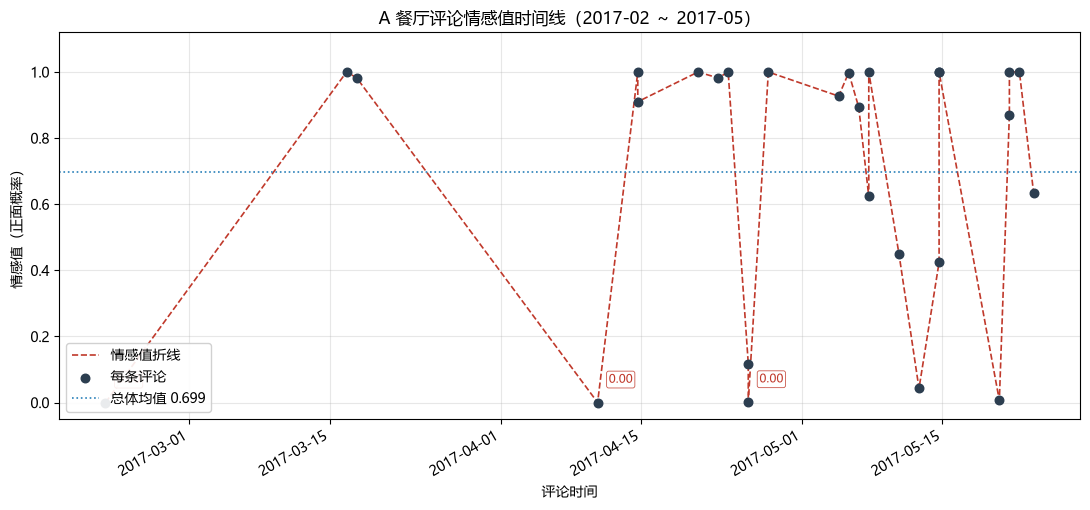

In [10]:
import matplotlib.pyplot as plt
from matplotlib import rcParams

# 中文字体（Windows 用微软雅黑/黑体；macOS 可换 Heiti TC；Linux 可换 Noto Sans CJK SC）
rcParams["font.sans-serif"] = ["Microsoft YaHei", "SimHei", "Heiti TC", "Noto Sans CJK SC"]
rcParams["axes.unicode_minus"] = False   # 解决负号显示成方块的问题

df = df.sort_values("date").reset_index(drop=True)

fig, ax = plt.subplots(figsize=(11, 5.2))
ax.plot(df["date"], df["sentiments"], color="#c0392b", linestyle="--", linewidth=1.2, label="情感值折线")
ax.scatter(df["date"], df["sentiments"], color="#2c3e50", s=38, zorder=3, label="每条评论")

mean_v = df.sentiments.mean()
ax.axhline(mean_v, color="#2980b9", linestyle=":", linewidth=1.2, label=f"总体均值 {mean_v:.3f}")

# 标出最低的 3 条，方便定位异常（用小气泡标注，避免压住折线/横轴）
for i in df.nsmallest(3, "sentiments").index:
    yi = df.loc[i, "sentiments"]
    ax.annotate(f"{yi:.2f}",
                (df.loc[i, "date"], yi),
                textcoords="offset points", xytext=(8, 12), ha="left", va="bottom",
                fontsize=8.5, color="#c0392b",
                bbox=dict(boxstyle="round,pad=0.18", fc="white", ec="#c0392b", lw=0.6, alpha=0.85))

ax.set_ylim(-0.05, 1.12)
ax.set_xlabel("评论时间")
ax.set_ylabel("情感值（正面概率）")
ax.set_title("A 餐厅评论情感值时间线（2017-02 ～ 2017-05）")
ax.grid(alpha=0.3)
ax.legend(loc="lower left", framealpha=0.9)
fig.autofmt_xdate()
plt.tight_layout()
plt.savefig("timeline.png", dpi=150, bbox_inches="tight")
plt.show()

> 与讲义代码的差异：讲义是 `plt.scatter(...)` 画散点；PPT 要求"**ggplot 函数绘制折线图（现在的代码是散点图）**"，
> 所以这里改成"散点 + 虚线折线"的组合，既保留每条评论的位置，又能看出趋势。

图上一眼可以看到两类点：
- 大量贴近 1.0 的点（非常满意）；
- 几条贴近 0 的点（严重不满），它们被折线连起来时会形成**深 V 形尖峰**。

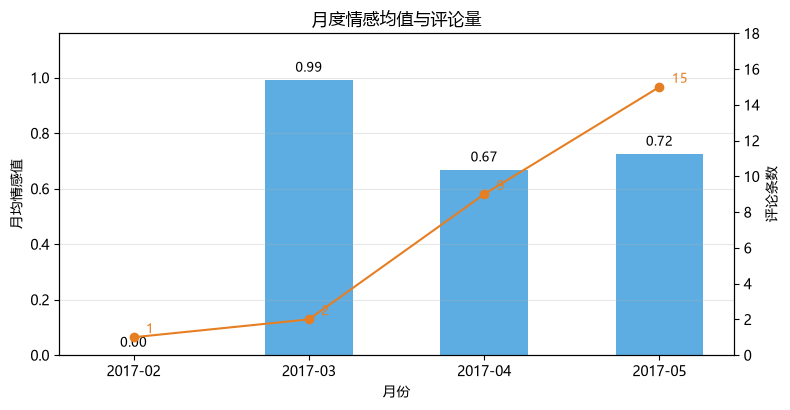

In [11]:
# 月度趋势：平均情感值（柱）+ 评论条数（折线，右轴）
monthly = df.set_index("date").resample("ME").agg(情感均值=("sentiments", "mean"), 评论数=("sentiments", "size"))
monthly.index = monthly.index.strftime("%Y-%m")

fig, ax1 = plt.subplots(figsize=(8, 4.2))
bars = ax1.bar(monthly.index, monthly["情感均值"], color="#5dade2", width=0.5, label="月均情感值")
ax1.set_ylim(0, 1.16)
ax1.set_ylabel("月均情感值")
ax1.set_xlabel("月份")

for b, v in zip(bars, monthly["情感均值"]):
    ax1.text(b.get_x() + b.get_width() / 2, v + 0.03, f"{v:.2f}", ha="center", fontsize=9)

ax2 = ax1.twinx()
ax2.plot(monthly.index, monthly["评论数"], color="#e67e22", marker="o", label="评论条数")
ax2.set_ylim(0, 18)
ax2.set_ylabel("评论条数")
for x, y in zip(monthly.index, monthly["评论数"]):
    ax2.annotate(str(int(y)), (x, y), textcoords="offset points", xytext=(9, 3),
                 ha="left", fontsize=9, color="#e67e22")

ax1.set_title("月度情感均值与评论量")
ax1.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig("月度趋势.png", dpi=150, bbox_inches="tight")
plt.show()

## 6. 定位异常评论

不用在 Excel 里一条条翻，`pandas` 的排序功能直接给出"情感值最低"的评论。

In [12]:
# 最低的 5 条：只显示日期、情感值和评论前 40 字
low5 = df.sort_values("sentiments").head(5)[["date", "sentiments", "comments"]].copy()
low5["comments"] = low5["comments"].str.slice(0, 40) + "…"
low5

,date,sentiments,comments
0,2017-02-20 16:00:00,6.334066e-08,这次是在情人节当天过去的，以前从来没在情人节正日子出来过，不是因为没有男朋友，而…
3,2017-04-10 16:00:00,1.965386e-04,服务好赞！外送小哥实际A餐厅自己配的，送之前一个电话说别急已经在送的路上，送到后…
10,2017-04-25 16:00:00,1.215408e-03,话说我真的很久很久没有吃A餐厅了，朋友想吃，我俩就过来了。她喜欢番茄锅，所以我们…
22,2017-05-20 16:00:00,6.392747e-03,A餐厅真的是天津每一个店我都来过无数次了！<br>今天觉得我拍的图很好看hhhh…
18,2017-05-12 16:00:00,4.267672e-02,今天又来到新开路的A餐厅，食材还是非常新鲜，羔羊肉味道鲜美，墨鱼滑味道新鲜！我们…


In [13]:
# 情感值最低的那一条，完整打印出来
print(df.sort_values(["sentiments"]).iloc[0].comments)

这次是在情人节当天过去的，以前从来没在情人节正日子出来过，不是因为没有男朋友，而是感觉哪哪人都多，所以特意错开，这次实在是馋A餐厅了，所以赶在正日子也出来了，从下午四点多的时候我看排号就排到一百多了，我从家开车过去得堵的话一个小时，我一看提前两个小时就在网上先排着号了，差不多我们是六点半到的，到那的时候我看号码前面还有才三十多号，我想着肯定没问题了，等一会就能吃上的，没想到悲剧了，就从我们到那坐到等位区开始，大约是十分二十分一叫号，中途多次我都想走了，哈哈，哎，等到最后早上九点才吃上的，服务员感觉也没以前清闲时周到了，不过这肯定的，一人负责好几桌，今天节日这么多人，肯定是很累的，所以大多也都是我自己跑腿，没让服务员给弄太多，就虾滑让服务员下的，然后环境来说感觉卫生方面是不错，就是有些太吵了，味道还是一如既往的那个味道，不过A餐厅最人性化的就是看我们等了两个多小时，上来送了我们一张打折卡，而且当次就可以使用，这点感觉还是挺好的，不愧是A餐厅，就是比一般的要人性化，不过这次就是选错日子了，以后还是得提前预约，要不就别赶节日去，太火爆了！


这条评论的情感值几乎就是 **0**。读一遍就能理解原因：

- 顾客在情人节当天排队，"从下午四点多排到晚上九点才吃上"，用了"**悲剧**""**太火爆**"等词；
- 服务员"没以前清闲时周到"，环境"太吵"——**负面词密集**；
- 但结尾又肯定"送了打折卡""不愧是A餐厅""比一般人性化"——所以人工判断是"**混合偏负**"，模型给 0 属于"过严"。

这个例子说明：**情感分析能帮我们快速定位异常，但不能完全代替人读评论**。

## 7. 作业分析

### 7.1 数据告诉我们什么

| 观察 | 数据依据 | 解读 |
|---|---|---|
| 总体口碑很好 | 中位数 0.927，75% 分位≈1.0，19/27 条正面 | 大多数顾客非常满意，属于"一边倒好评"型门店 |
| 平均分被少数差评拉低 | 均值 0.699 << 中位数 0.927，标准差 0.401 | 存在若干"极端负面"离群点，不能只看平均分 |
| 差评不是集中在某一天 | 最低 5 条分布在 2/20、4/10、4/25、5/12、5/20 | 更像"服务/排队"的结构性问题，而不是某次偶发事故 |
| 4—5 月评论量最大 | 4 月 9 条、5 月 15 条 | 越靠近旺季，负面体验越容易被放大，需要提前排班 |

### 7.2 如果我是经理，我会做什么

1. **排队时长可视化**：把"等待时长"作为独立字段记录，和情感值做相关分析——最低分那条正是排队 3 小时以上；
2. **差评回访机制**：对情感值 $\le 0.2$ 的评论自动推送给店长，24 小时内回访；
3. **服务人力排班**：情人节、周末等高峰日按客流量增加服务员，避免"一人负责好几桌"；
4. **预约分流**：引导顾客线上排号、错峰到店，把"等待预期"讲清楚。

### 7.3 方法的局限

- SnowNLP 给的是"正面概率"，不是严格的 $-1\sim+1$ 极性，**不能把 0.5 当成绝对中性**；
- 长评论会被"平均"，褒贬混杂时分数不稳定（第 1 条就是例子）；
- 单条低分不等于门店差，需结合文本内容人工复核；
- 词典/分类器对反讽、网络新词不敏感，这也是后面要用大模型的原因。

## 8. 小结

- 跑通了"Excel → 批量情感值 → 折线图 → 异常定位"的完整流程；
- 用 `mean` / `median` 的差异发现了"总体好评 + 少量极端差评"的结构；
- 把最低分评论定位到"情人节排队 3 小时"这一具体事件，并给出可执行的服务改进建议；
- 生成的文件：`timeline.png`（折线图）、`月度趋势.png`、`程序2_评论情感值.xlsx`。